# Peak stacking on the Planck CMB map

This tutorial stacks the temperature peaks of the real Planck PR3 SMICA map. Unlike the simulated full-sky map of the first tutorial, the real map has to be masked: the Galactic plane and bright point sources are removed with the Planck common intensity mask, which covers about 22% of the sky.

It shows how `cmbstack` handles a masked map:

1. The mask of an `hp.ma` array is kept, and the map is normalised on unmasked pixels only.
2. Peaks next to the mask are discarded, and `mask_distance_deg` widens this cut.
3. Masked pixels are ignored in each patch, and the stack counts how many patches contribute to each pixel.

## Data

Download the SMICA map (about 1.9 GB) and the common intensity mask (about 200 MB) from the [Planck Legacy Archive at IRSA](https://irsa.ipac.caltech.edu/data/Planck/release_3/):

```bash
BASE=https://irsa.ipac.caltech.edu/data/Planck/release_3
wget -c "$BASE/all-sky-maps/maps/component-maps/cmb/COM_CMB_IQU-smica_2048_R3.00_full.fits"
wget -c "$BASE/ancillary-data/masks/COM_Mask_CMB-common-Mask-Int_2048_R3.00.fits"
```

Set `data_dir` to the folder holding both files.

In [1]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt

from cmbstack import StackingPipeline

In [2]:
data_dir = 'data'

map_fname = data_dir + '/COM_CMB_IQU-smica_2048_R3.00_full.fits'
mask_fname = data_dir + '/COM_Mask_CMB-common-Mask-Int_2048_R3.00.fits'

## Load the map and the mask

Field 0 of the SMICA file is the temperature map (`I_STOKES`, in $K_{CMB}$) at $N_{side} = 2048$. The mask is 1 on the pixels to keep and 0 on the pixels to remove.

A `healpy` masked array (`hp.ma`) uses the opposite convention: its `mask` is True where a pixel is *removed*, so it is set to `np.logical_not(mask)`.

In [3]:
cmb_map = hp.read_map(map_fname, field=0)
mask = hp.read_map(mask_fname, field=0).astype(bool)

cmb_map_masked = hp.ma(cmb_map)
cmb_map_masked.mask = np.logical_not(mask)

print(f'Masked fraction of the sky: {1 - mask.mean():.1%}')

Masked fraction of the sky: 22.1%


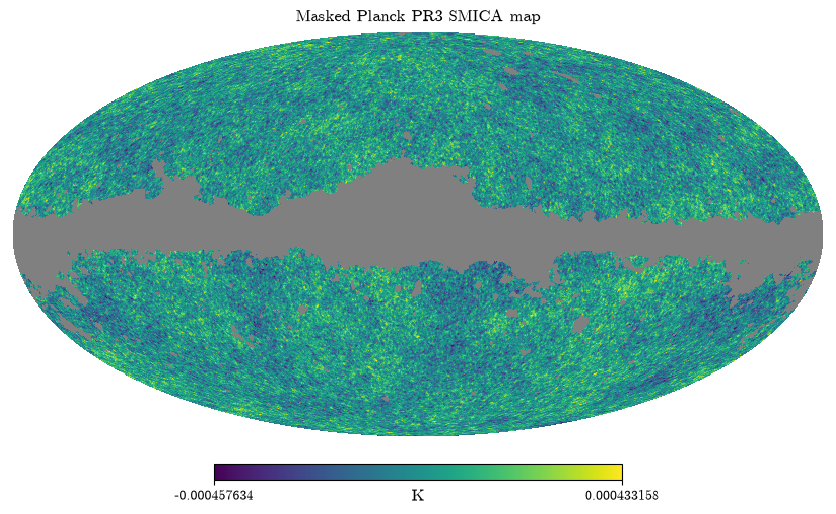

In [4]:
hp.mollview(cmb_map_masked, title='Masked Planck PR3 SMICA map', unit='K')
plt.show()

## Stack the peaks

`StackingPipeline.from_map` keeps the mask of the `hp.ma` array: masked pixels are stored as `hp.UNSEEN`, and `normalize_map` computes the mean and standard deviation from the unmasked pixels only.

`find_peaks` never returns a masked pixel. It also drops any peak with a masked neighbour, because such a pixel only has to be higher than its unmasked neighbours to count as a maximum. `verbose=True` prints how many peaks were kept and how many were rejected.

The defaults are 10° × 10° patches with 3′ pixels and peaks above $3\sigma$.

In [5]:
pipeline_masked = StackingPipeline.from_map(cmb_map_masked)
pipeline_masked.run(verbose=True);

find_peaks: kept 3934 peaks, rejected 18523 near the mask


The patches of peaks close to the mask still contain masked pixels. A wider exclusion zone around the mask removes those peaks too, at the cost of fewer patches:

`run()` returns the pipeline itself and overwrites its results, so each setting gets its own pipeline.

In [6]:
pipeline_masked_1deg = StackingPipeline.from_map(cmb_map_masked)
pipeline_masked_1deg.run(mask_distance_deg=1.0, verbose=True);

find_peaks: kept 2396 peaks, rejected 341240 near the mask


The rejected numbers are counted before the $3\sigma$ threshold, so they include low peaks that the threshold would have dropped anyway.

Peak positions are `(lon, lat)` in degrees, here Galactic longitude and latitude, so they are plotted with `lonlat=True`:

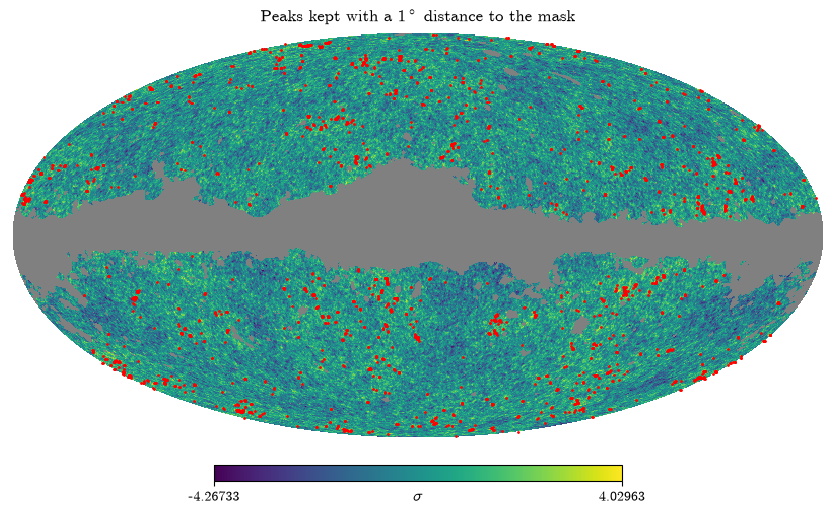

In [7]:
hp.mollview(pipeline_masked_1deg.normalized, title=r'Peaks kept with a 1$^\circ$ distance to the mask', unit=r'$\sigma$')
hp.projscatter(pipeline_masked_1deg.positions[:, 0], pipeline_masked_1deg.positions[:, 1],
               color='red', s=1, lonlat=True)
plt.show()

## Per-pixel counts

Masked pixels become NaN in each patch, and `stack_patches` divides each pixel by the number of patches with a valid value there. `pipeline.counts` stores that number. The maximum equals the number of patches. The counts drop towards the edges of the patch, which reach the mask for peaks closer than 5° to it; with the 1° cut, every patch contributes within 1° of the centre:

neighbour cut: 3934 patches, counts from 3438 to 3934
1 deg cut: 2396 patches, counts from 2178 to 2396


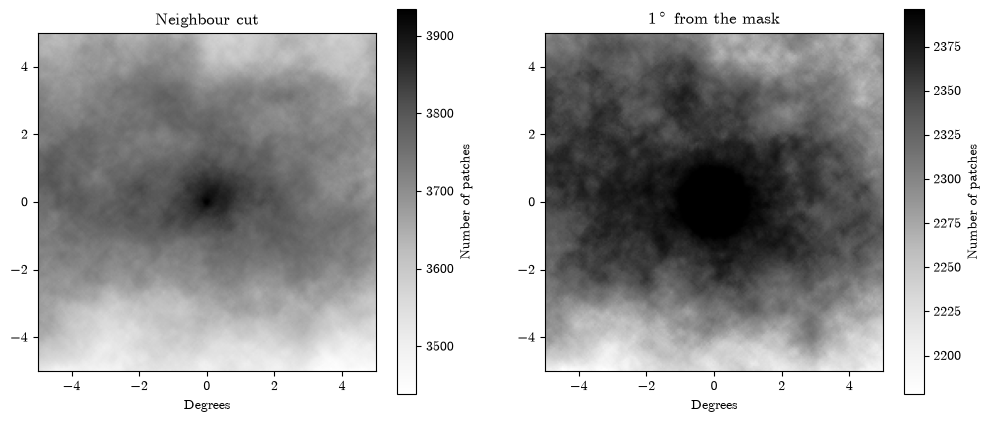

In [8]:
for name, p in [('neighbour cut', pipeline_masked), ('1 deg cut', pipeline_masked_1deg)]:
    print(f'{name}: {len(p.positions)} patches, counts from {p.counts.min()} to {p.counts.max()}')

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, p, title in zip(axs, [pipeline_masked, pipeline_masked_1deg], ['Neighbour cut', r'1$^\circ$ from the mask']):
    im = ax.imshow(p.counts, origin='lower', cmap='Greys', extent=[-5, 5, -5, 5])
    ax.set_title(title)
    ax.set_xlabel('Degrees')
    fig.colorbar(im, ax=ax, label='Number of patches')
plt.show()

## Masked against unmasked

For comparison, the unmasked map is stacked too. Its peaks include the Galactic plane and point sources, which the mask removes.

In [9]:
pipeline_unmasked = StackingPipeline.from_map(cmb_map)
pipeline_unmasked.run(verbose=True);

find_peaks: kept 5457 peaks, rejected 0 near the mask


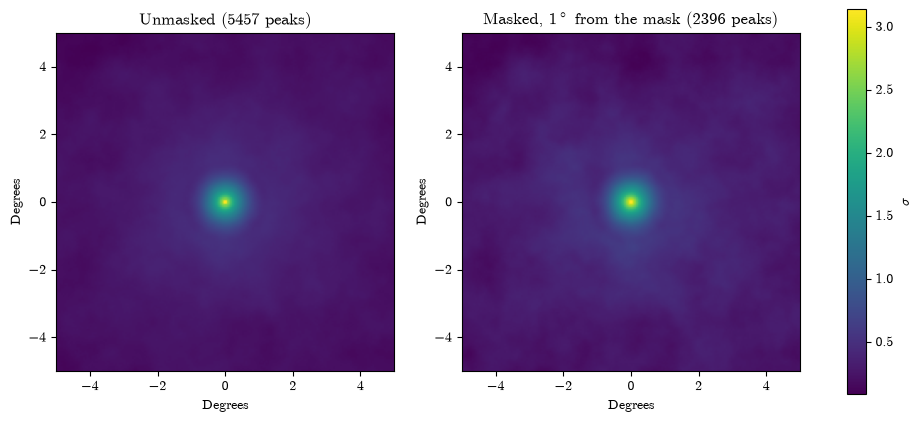

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, p, title in zip(axs, [pipeline_unmasked, pipeline_masked_1deg], ['Unmasked', r'Masked, 1$^\circ$ from the mask']):
    ax.imshow(p.stacked, origin='lower', extent=[-5, 5, -5, 5])
    ax.set_title(f'{title} ({len(p.positions)} peaks)')
    ax.set_xlabel('Degrees')
    ax.set_ylabel('Degrees')
fig.colorbar(axs[1].images[0], ax=axs, label=r'$\sigma$')
plt.show()

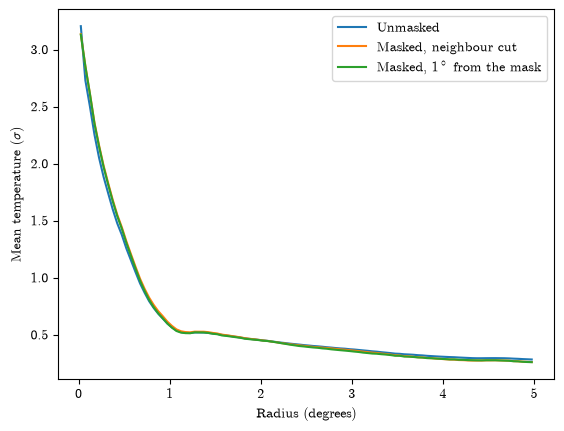

In [11]:
for p, label in [(pipeline_unmasked, 'Unmasked'), (pipeline_masked, 'Masked, neighbour cut'),
                 (pipeline_masked_1deg, r'Masked, 1$^\circ$ from the mask')]:
    plt.plot(p.radius / 60, p.profile, label=label)
plt.xlabel('Radius (degrees)')
plt.ylabel(r'Mean temperature ($\sigma$)')
plt.legend()
plt.show()